<a href="https://colab.research.google.com/github/sifontheengine/Sales-and-Revenue-Intelligence-Analysis-/blob/main/Sales%26RevenueIntelligenceAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Install and import libraries

In [2]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import plotly.express as px

# Machine Learning (for forecasting later)
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [3]:
# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [1]:
from google.colab import files
uploaded = files.upload()

Saving sample_-_superstore.xls to sample_-_superstore.xls


Load dataset

In [4]:
df = pd.read_excel("sample_-_superstore.xls")

In [5]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


Explore the dataset

In [6]:
# Shape of the dataset
print("Rows and Columns:", df.shape)

# Columns names
print("\nColumns")
print(df.columns)

# Data types
print("\nData Types")
print(df.columns)

# Basic statistics
print("\nSummary Statistics:")
df.describe(include="all")

Rows and Columns: (9994, 21)

Columns
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

Data Types
Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

Summary Statistics:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
count,9994.000000,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994,9994.000000,9994,9994,9994,9994,9994,9994.000000,9994.000000,9994.000000,9994.000000
unique,NaN,5009,NaN,NaN,4,793,793,3,1,531,49,NaN,4,1862,3,17,1850,NaN,NaN,NaN,NaN
top,NaN,CA-2017-100111,NaN,NaN,Standard Class,WB-21850,William Brown,Consumer,United States,New York City,California,NaN,West,OFF-PA-10001970,Office Supplies,Binders,Staple envelope,NaN,NaN,NaN,NaN
freq,NaN,14,NaN,NaN,5968,37,37,5191,9994,915,2001,NaN,3203,19,6026,1523,48,NaN,NaN,NaN,NaN
mean,4997.500000,NaN,2016-04-30 00:07:12.259355648,2016-05-03 23:06:58.571142912,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55190.379428,NaN,NaN,NaN,NaN,NaN,229.858001,3.789574,0.156203,28.656896
min,1.000000,NaN,2014-01-03 00:00:00,2014-01-07 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1040.000000,NaN,NaN,NaN,NaN,NaN,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,NaN,2015-05-23 00:00:00,2015-05-27 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23223.000000,NaN,NaN,NaN,NaN,NaN,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,NaN,2016-06-26 00:00:00,2016-06-29 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56430.500000,NaN,NaN,NaN,NaN,NaN,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,NaN,2017-05-14 00:00:00,2017-05-18 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90008.000000,NaN,NaN,NaN,NaN,NaN,209.940000,5.000000,0.200000,29.364000
max,9994.000000,NaN,2017-12-30 00:00:00,2018-01-05 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,99301.000000,NaN,NaN,NaN,NaN,NaN,22638.480000,14.000000,0.800000,8399.976000


Check for missing values

In [7]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


Check for Duplicate records

In [8]:
# Number of duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


Make a copy of the dataset

In [9]:
sales = df.copy()

View dataset information

In [10]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

Look for

* Number of rows and columns
* Data types
* Missing values

In [11]:
print("Duplicates before: ", sales.duplicated().sum())

sales = sales.drop_duplicates()

print("Duplicates after: ", sales.duplicated().sum())

Duplicates before:  0
Duplicates after:  0


Handling missing values

In [12]:
sales.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


If there are only a few missing values:

In [13]:
sales = sales.dropna()

If a numeric column has missing values

In [14]:
sales["Sales"] = sales["Sales"].fillna(sales["Sales"].mean())

If a categorical column has missing values

In [15]:
sales["Category"] = sales["Sales"].fillna("Unknown")

Convert Dates

Business analysis depends heavily on dates.

In [16]:
sales["Order Date"] = pd.to_datetime(sales["Order Date"])
sales["Ship Date"] = pd.to_datetime(sales["Ship Date"])

Verify:

In [17]:
sales.dtypes

,0
Row ID,int64
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


Create business features

These features make analysis much easier

Year

In [18]:
sales["Year"] = sales["Order Date"].dt.year

Month Name

In [19]:
sales["Month"] = sales["Order Date"].dt.month

Month Number

In [20]:
sales["Month No"] = sales["Order Date"].dt.month

Quarter

In [21]:
sales["Quarter"] = sales["Order Date"].dt.quarter

Day of week

In [22]:
sales["Day"] = sales["Order Date"].dt.day_name()

Create Business KPIs

Profit Margin (%)

In [23]:
sales["Profit Margin"] = (
    sales["Profit"] / sales["Sales"]
) * 100

Revenue per Item

In [24]:
sales["Revenue per Item"] = (
    sales["Sales"] / sales["Quantity"]
)

Shopping Time

In [25]:
sales["Shipping Days"] = (
    sales["Ship Date"] - sales["Order Date"]
).dt.days

Inspect the New Dataset

In [26]:
sales.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Month No,Quarter,Day,Profit Margin,Revenue per Item,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,261.9600,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,11,4,Tuesday,16.00,130.9800,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,731.9400,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,11,4,Tuesday,30.00,243.9800,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,14.6200,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,6,2,Sunday,47.00,7.3100,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,957.5775,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,10,4,Sunday,-40.00,191.5155,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,22.3680,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,10,4,Sunday,11.25,11.1840,7


Executive KPIs

In [27]:
total_revenue = sales["Sales"].sum()

# Total Profit
total_profit = sales["Profit"].sum()

# Total Orders
total_orders = sales["Order ID"].nunique()

# Total Customers
total_customers = sales["Customer ID"].nunique()

# Average Order Value
# Calculate a single scalar for Average Order Value (Total Revenue / Total Orders)
average_order_value = total_revenue / total_orders

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders}")
print(f"Total Customers: {total_customers}")
print(f"Average Order Value: ${average_order_value:,.2f}")

Total Revenue: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5009
Total Customers: 793
Average Order Value: $458.61


Monthly Revenue Trend

This helps identify seasonal patterns

In [28]:
monthly_sales = (
   sales.groupby(["Year","Month No","Month"])["Sales"]
   .sum()
   .reset_index()
   .sort_values(["Year", "Month No"])
)

monthly_sales

,Year,Month No,Month,Sales
0,2014,1,1,14236.8950
1,2014,2,2,4519.8920
2,2014,3,3,55691.0090
3,2014,4,4,28295.3450
4,2014,5,5,23648.2870
5,2014,6,6,34595.1276
6,2014,7,7,33946.3930
7,2014,8,8,27909.4685
8,2014,9,9,81777.3508
9,2014,10,10,31453.3930


Plot the trend

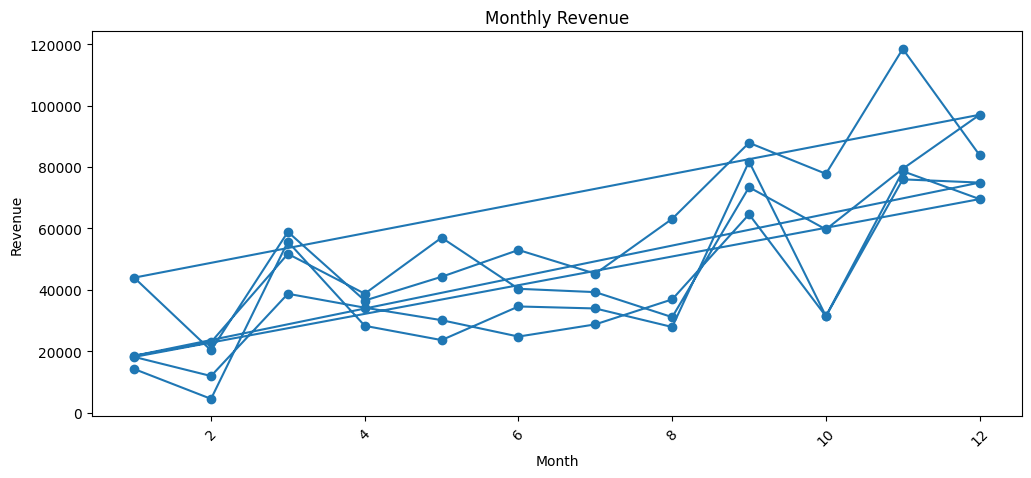

In [29]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Sales"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.show()

Revenue by Region

In [30]:
region_sales = (
    sales.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

region_sales

,Sales
Region,
West,725457.8245
East,678781.2400
Central,501239.8908
South,391721.9050


Bar Chart

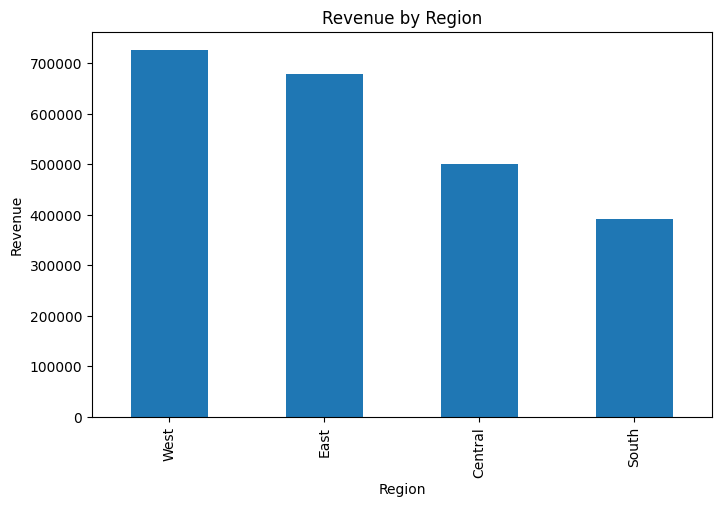

In [31]:
region_sales.plot(
   kind="bar",
   figsize=(8,5)
)

plt.title("Revenue by Region")
plt.ylabel("Revenue")

plt.show()

Profit by Category

In [32]:
category_profit = (
    sales.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

category_profit

,Profit
Category,
17499.950,8399.9760
13999.960,6719.9808
10499.970,5039.9856
9892.740,4946.3700
4899.930,4703.9328
...,...
1889.990,-2929.4845
2549.985,-3399.9800
2177.584,-3701.8928


Visualization

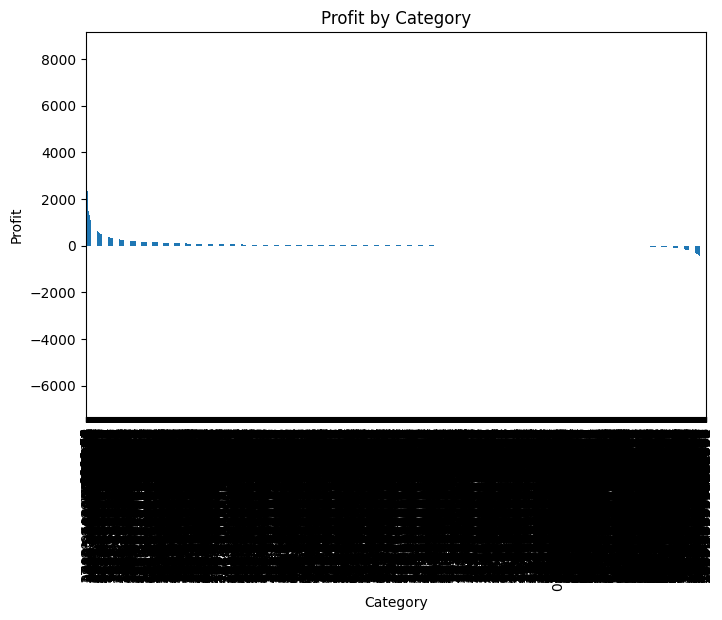

In [33]:
category_profit.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Profit by Category")
plt.ylabel("Profit")

plt.show()

Top 10 Customers

In [34]:
top_customers = (
    sales.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_customers

,Sales
Customer Name,
Sean Miller,25043.050
Tamara Chand,19052.218
Raymond Buch,15117.339
Tom Ashbrook,14595.620
Adrian Barton,14473.571
Ken Lonsdale,14175.229
Sanjit Chand,14142.334
Hunter Lopez,12873.298
Sanjit Engle,12209.438


Visualization

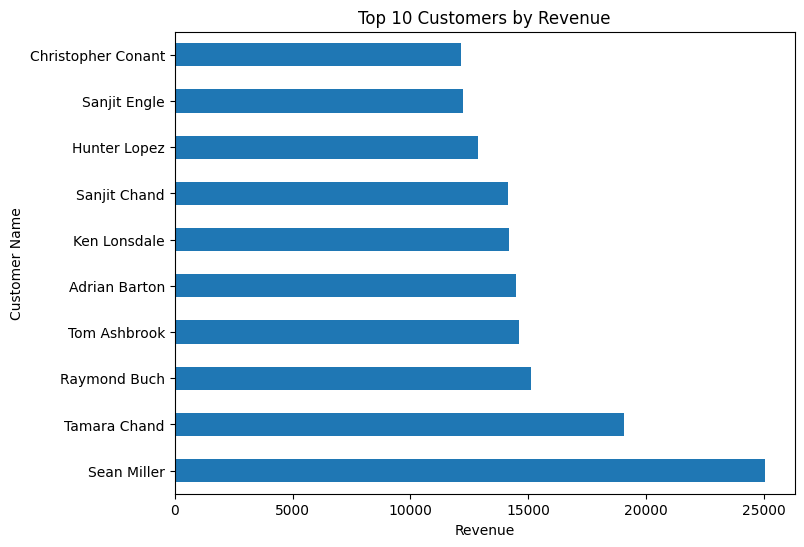

In [35]:
top_customers.plot(
    kind="barh",
    figsize=(8,6)
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")

plt.show()

Top 10 Products

In [36]:
top_products = (
    sales.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

,Sales
Product Name,
Canon imageCLASS 2200 Advanced Copier,61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480
HON 5400 Series Task Chairs for Big and Tall,21870.576
GBC DocuBind TL300 Electric Binding System,19823.479
GBC Ibimaster 500 Manual ProClick Binding System,19024.500
Hewlett Packard LaserJet 3310 Copier,18839.686
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895
GBC DocuBind P400 Electric Binding System,17965.068


Visualization

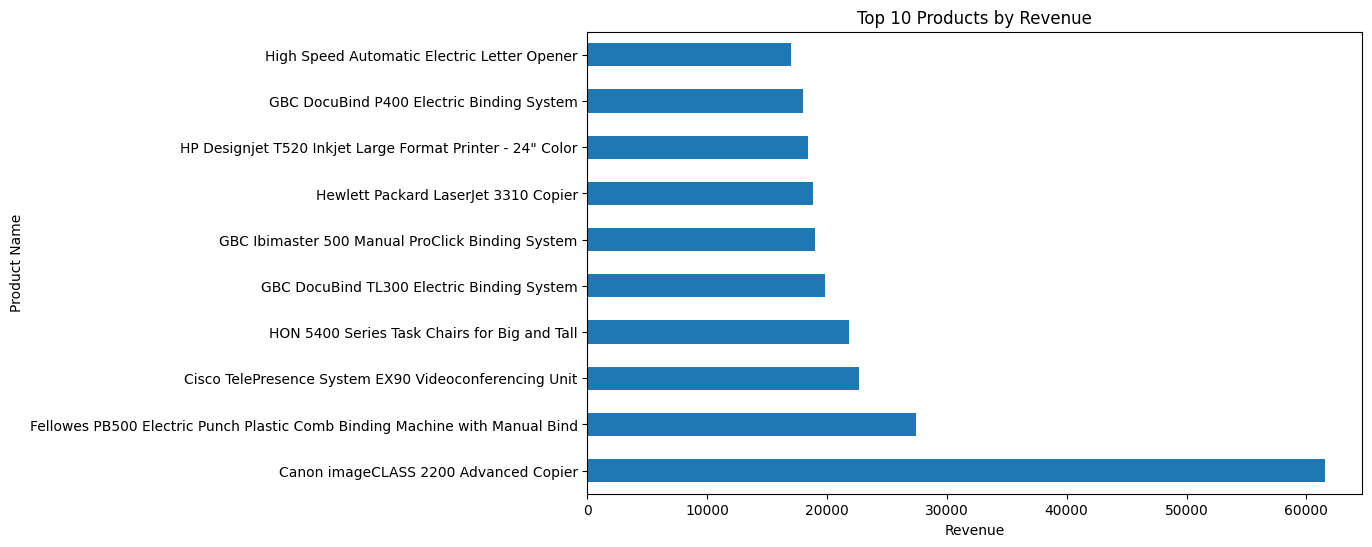

In [37]:
top_products.plot(
    kind="barh",
    figsize=(10,6)
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")

plt.show()

Profit Margin Analysis

* Let's see how predictable each product category is

In [38]:
category_summary = (
    sales.groupby("Category")
    .agg(
        Revenue=("Sales","sum"),
        Profit=("Profit","sum")
    )
)

category_summary["Profit Margin (%)"] = (
    category_summary["Profit"] /
    category_summary["Revenue"]
) * 100

category_summary

,Revenue,Profit,Profit Margin (%)
Category,,,
0.444,0.444,-1.1100,-250.0
0.556,0.556,-0.9452,-170.0
0.836,0.836,-1.3376,-160.0
0.852,0.852,-0.5964,-70.0
0.876,0.876,-1.4016,-160.0
...,...,...,...
10499.970,10499.970,5039.9856,48.0
11199.968,11199.968,3919.9888,35.0
13999.960,13999.960,6719.9808,48.0


Visualize profit margin

In [ ]:
category_summary["Profit Margin (%)"].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Profit Margin by Category")
plt.ylabel("Profit Margin (%)")

plt.show()

Sales vs Profit

This helps determine whether higher sales actually lead to higher profits.

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(
    sales["Sales"],
    sales["Profit"]
)

plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")

plt.show()

State-wise Sales Analysis

In [ ]:
state_sales = (
    sales.groupby("State")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

state_sales.head(10)

Sub-Category Analysis

* This gives more detail than the broader product categories.

In [ ]:
subcategory = (
    sales.groupby("Sub-Category")
    .agg(
        Revenue=("Sales","sum"),
        Profit=("Profit","sum")
    )
    .sort_values("Revenue", ascending=False)
)

subcategory.head(10)

Visualization

In [ ]:
subcategory["Revenue"].head(10).plot(
    kind="barh",
    figsize=(10,6)
)

plt.title("Top 10 Sub-Categories")
plt.xlabel("Revenue")

plt.show()

Discount impact

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    sales["Discount"],
    sales["Profit"]
)

plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")

plt.show()

This chart often reveals that:

* Higher discounts tend to reduce profits
* Some heavily discounted orders even result in losses.

Shipping performance

* Let's calculate the average shipping time.

In [ ]:
sales["Shipping Days"].describe()

Average shipping days:

In [ ]:
sales["Shipping Days"].mean()

Shipping time by shipping mode:

In [ ]:
sales.groupby("Ship Mode")["Shipping Days"].mean()

Pareto Analysis (80/20 Rule)

The Pareto principle states that roughly 80% of revenue often comes from 20% of customers. Let's test whether that's time for our dataset

Calculate Customer Revenue

In [ ]:
customer_sales = (
    sales.groupby("Customer Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

customer_sales.columns = ["Customer Name", "Revenue"]

Calculate Cumulative Revenue

In [ ]:
customer_sales["Cumulative Revenue"] = customer_sales["Revenue"].cumsum()

customer_sales["Cumulative Percentage"] = (
    customer_sales["Cumulative Revenue"] /
    customer_sales["Revenue"].sum()
) * 100

customer_sales.head()

Plot the Pareto chart

In [ ]:
plt.figure(figsize=(12,6))

plt.bar(
    customer_sales["Customer Name"],
    customer_sales["Revenue"]
)

plt.plot(
    customer_sales["Cumulative Percentage"],
    color="red",
    marker="o"
)

plt.axhline(80, color="green", linestyle="--")

plt.xticks([])

plt.title("Pareto Analysis of Customer Revenue")
plt.ylabel("Revenue / Cumulative %")

plt.show()

Customer segmentation

Let's classify customers into High, Medium, and Low spenders.

In [ ]:
customer_summary = (
    sales.groupby("Customer Name")
    .agg(
        Revenue=("Sales","sum"),
        Orders=("Order ID","nunique"),
        Profit=("Profit","sum")
    )
)

customer_summary.head()

Create spending segments

In [ ]:
customer_summary["Segment"] = pd.qcut(
    customer_summary["Revenue"],
    q=3,
    labels=["Low Value","Medium Value","High Value"]
)

customer_summary.head()

Count customers per segment

In [ ]:
customer_summary["Segment"].value_counts()

Visualize the segments

In [ ]:
customer_summary["Segment"].value_counts().plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Customer Segments")
plt.ylabel("Number of Customers")

plt.show()

Interactive dashboard with poorly

Interactive charts are much more engaging them static ones

Monthly Revenue

In [ ]:
fig = px.line(
    monthly_sales,
    x="Month",
    y="Sales",
    title="Monthly Revenue Trend",
    markers=True
)

fig.show()

Revenue by Region

In [ ]:
fig = px.bar(
    region_sales.reset_index(),
    x="Region",
    y="Sales",
    title="Revenue by Region"
)

fig.show()

Category Revenue

In [ ]:
category_sales = (
    sales.groupby("Category")["Sales"]
    .sum()
    .reset_index()
)

fig = px.pie(
    category_sales,
    names="Category",
    values="Sales",
    title="Revenue by Category"
)

fig.show()

Prepare the Data for forecasting.

We'll forecast daily sales

In [ ]:
# Aggregate sales by order date
daily_sales = (
    sales.groupby("Order Date")["Sales"]
    .sum()
    .reset_index()
)

daily_sales.head()

Create a time index

Machine Learning models work with numbers rather than dates.

In [ ]:
daily_sales["Day"] = range(len(daily_sales))

daily_sales.head()

Train a Linear Regression model

In [ ]:
X = daily_sales[["Day"]]
y = daily_sales["Sales"]

model = LinearRegression()
model.fit(X,y)

print("Model trained successfully!")

Predict historical sales

In [ ]:
daily_sales["Predicted Sales"] = model.predict(X)

daily_sales.head()

Compare Actual vs Predicted Sales

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    daily_sales["Order Date"],
    daily_sales["Sales"],
    label="Actual Sales"
)

plt.plot(
    daily_sales["Order Date"],
    daily_sales["Predicted Sales"],
    label="Predicted Sales"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()

plt.show()

Forecast the next 30 days

In [ ]:
feature_days = pd.DataFrame({
     "Day": range(
         len(daily_sales),
         len(daily_sales) + 30
     )
})

future_predictions = model.predict(feature_days)

future_predictions

Create Future Dates

In [ ]:
future_dates = pd.date_range(
    start = daily_sales["Order Date"].max() + pd.Timedelta(days=1),
    periods=30
)

forecast = pd.DataFrame({
    "Date": future_dates,
    "Forecast Sales": future_predictions
})

forecast.head()

Pot the Forecast

In [ ]:
plt.figure(figsize=(14,6))

plt.plot(
    daily_sales["Order Date"],
    daily_sales["Sales"],
    label="Historical Sales"
)

plt.plot(
    forecast["Date"],
    forecast["Forecast Sales"],
    label="Forecast",
    linestyle="--"
)

plt.title("30-Day Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()

plt.show()

Evaluate the model

Let's see how well the model fits the historical data.

In [ ]:
mae = mean_absolute_error(
    daily_sales["Sales"],
    daily_sales["Predicted Sales"]
)

mse = mean_squared_error(
    daily_sales["Sales"],
    daily_sales["Predicted Sales"]
)

r2 = r2_score(
   daily_sales["Sales"],
   daily_sales["Predicted Sales"]
)

print(f"Mean Absolute Error: {mae:.2f}")
print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2:.4f}")